In [39]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

Hs = 7 #m wave height
h = 25 #m depth 
St = 0.15 #steepness
pi = np.pi
g = 9.81

Lambda = pi * Hs/St

Tp = np.sqrt(Lambda / np.tanh(2*pi*h/Lambda) * 2 *pi /g)

print(f"Wavelength: {Lambda:.2f} m")
print(f"Tp: {Tp:.2f} s")

Wavelength: 146.61 m
Tp: 10.90 s


Peak period: 15.15 s
Peak frequency: 0.0660 Hz


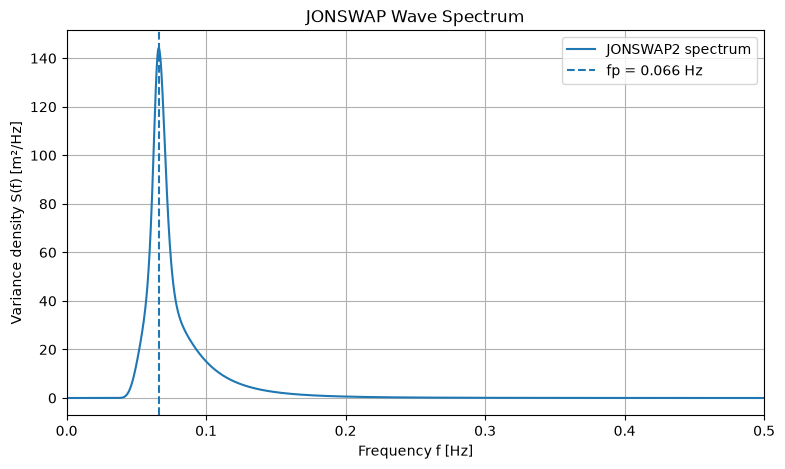

In [23]:

import matplotlib.pyplot as plt

# JONSWAP parameters
gamma = 3.3
fp = 1 / Tp

# Frequency range (avoid f = 0)
f = np.linspace(0.001, 1.0, 5000)

# Spectral width
sigma = np.where(f <= fp, 0.07, 0.09)

# Peak enhancement exponent
r = np.exp(-(f - fp)**2 / (2 * sigma**2 * fp**2))

# Pierson-Moskowitz

Epm = 5/16*Hs**2*fp**4*f**-5*np.exp(-5/4*(fp/f)**4)
Alpha = 1-0.287*np.log(gamma)

# JONSWAP spectral shape (initially alpha = 1)
#S = (g**2 / ((2*np.pi)**4 * f**5)) * \
    #np.exp(-1.25 * (fp/f)**4) * gamma**r
S2 = Alpha*Epm*gamma**r


print(f"Peak period: {Tp:.2f} s")
print(f"Peak frequency: {fp:.4f} Hz")


# Plot spectrum
plt.figure(figsize=(9, 5))
#plt.plot(f, S, label="JONSWAP spectrum")
plt.plot(f,S2, label="JONSWAP2 spectrum")
plt.axvline(fp, linestyle="--", label=f"fp = {fp:.3f} Hz")

plt.xlabel("Frequency f [Hz]")
plt.ylabel("Variance density S(f) [m²/Hz]")
plt.title("JONSWAP Wave Spectrum")
plt.legend()
plt.grid(True)
plt.xlim(0, 0.5)
plt.show()


In [36]:
m0_test = Hs**2/16
m0 = np.trapezoid(S2, f)
Hs_0 = 4 * np.sqrt(m0)

m_minus1 = np.trapezoid(S2/f, f)
m1 = np.trapezoid(f*S2, f)
m2 = np.trapezoid(f**2*S2,f)



print(f"m0_test: {m0_test}")
print(f"m0: {m0}")
print(f"Hs_0: {Hs_0}")

print(f"m-1 = {m_minus1:.4f} m²s")
print(f"m1  = {m1:.4f} m²/s")
print(f"m2  = {m2:.4f} m²/s²")


Tm = np.sqrt(m0 / m2)
Tm_10 = m_minus1 / m0
Tm01 = m0 / m1

print(f"Tm  = {Tm:.2f} s")
print(f"Tm-10 = {Tm_10:.2f} s")
print(f"Tm01  = {Tm01:.2f} s")

m0_test: 3.0625
m0: 3.0698521060620085
Hs_0: 7.008397370083416
m-1 = 42.0220 m²s
m1  = 0.2427 m²/s
m2  = 0.0220 m²/s²
Tm  = 11.81 s
Tm-10 = 13.69 s
Tm01  = 12.65 s


In [ ]:
from scipy.optimize import newton

k = newton(
    func=lambda k: g*k*np.tanh(k*h) - omega**2,
    x0=omega**2/g,
    fprime=lambda k: (
        g*np.tanh(k*h)
        + g*k*h/np.cosh(k*h)**2
    )
)

L = 2*np.pi/k
s = Hs/L

lambda2; 1386.7842402209342
